# DL 05 — Shared-trunk multitask model, integrated evaluation and AML comparison

This is the main Phase 2 notebook. It trains the **shared-trunk multitask network** required by the project specification and evaluates it against the AML Random Forest baseline and the DL single-task ablations.

```
1,046 predictors ─ input dropout ─ [Linear → BatchNorm → ReLU → Dropout] × k   (shared trunk)
                                      ├─ building head   → 3 logits
                                      ├─ floor head      → 5 logits
                                      └─ coordinate head → 2 standardized coordinates
loss = w_b·CE(building) + w_f·CE(floor) + w_c·SmoothL1_β(coordinates)
```

**Model selection.** Every candidate in `config.SELECTION_GRID` (width/depth, dropout, loss weights, Smooth-L1 β) is trained on internal training with AdamW, ReduceLROnPlateau and early stopping (patience 15) on the internal-validation score:

`score = mean(building error rate, floor error rate, mean Euclidean error ÷ centroid-baseline error)`.

The lowest score wins. The configuration is saved **before** the held-out file is loaded. The frozen configuration is then retrained with two more seeds to show seed variability; seeds are not used to choose anything.

**Fair comparison.** AML and DL use the same internal split, the same 1,046-feature contract, the same held-out rows (joined on `SOURCE_PARTITION`, `ROW_ID`) and the same metric definitions. Coordinate errors are in **dataset coordinate units**.

In [1]:
from pathlib import Path
import sys

def find_project_root(start=None):
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (parent / "data/raw").is_dir() and (parent / "src/signal2space_dl").is_dir():
            return parent
    raise FileNotFoundError("Run this notebook from inside the Signal2Space repository")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import platform
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from signal2space_dl import config as C, multitask

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | torch {torch.__version__}")
print("Repository root:", PROJECT_ROOT)

Python 3.13.18 | pandas 3.1.1 | torch 2.15.0+cu132
Repository root: /home/user/Signal2Space


## 1. Select, train and evaluate the multitask model

In [2]:
result = multitask.run_multitask()
display(result["selection"])

mt_512x256_d30               score=0.0355 best_epoch=26 (40s)


mt_1024x512_d30              score=0.0438 best_epoch=63 (117s)


mt_512x256_d50               score=0.0489 best_epoch=15 (33s)


mt_1024x512x256_d30          score=0.0360 best_epoch=15 (47s)


mt_512x256_d30_floorx2       score=0.0367 best_epoch=57 (70s)


mt_512x256_d30_coordx2       score=0.0346 best_epoch=25 (38s)


mt_512x256_d30_beta1         score=0.0375 best_epoch=46 (58s)


,config,hidden_sizes,head_hidden,dropout,input_dropout,learning_rate,weight_decay,batch_size,max_epochs,patience,w_building,w_floor,w_coord,coord_beta,tasks,seed,best_epoch,epochs_run,val_selection_score,val_building_acc,val_floor_acc,val_mean_euclidean,n_parameters,train_seconds,selected
0,mt_512x256_d30_coordx2,"[512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,2.0,0.1,"[building, floor, coord]",42,25,40,0.034582,0.999221,0.978712,10.281026,768906,38.0,True
1,mt_512x256_d30,"[512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,"[building, floor, coord]",42,26,41,0.035497,0.999221,0.977934,10.528547,768906,40.4,False
2,mt_1024x512x256_d30,"[1024, 512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,"[building, floor, coord]",42,15,30,0.036001,0.999221,0.979751,10.947625,1831818,47.4,False
3,mt_512x256_d30_floorx2,"[512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,2.0,1.0,0.1,"[building, floor, coord]",42,57,72,0.036707,0.999221,0.974559,10.560670,768906,70.0,False
4,mt_512x256_d30_beta1,"[512, 256]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,1.0,"[building, floor, coord]",42,46,61,0.037484,0.999221,0.978453,11.344494,768906,58.0,False
5,mt_1024x512_d30,"[1024, 512]",128,0.3,0.1,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,"[building, floor, coord]",42,63,78,0.043753,0.998442,0.976895,13.417343,1798282,116.7,False
6,mt_512x256_d50,"[512, 256]",128,0.5,0.2,0.001,0.0001,256,150,15,1.0,1.0,1.0,0.1,"[building, floor, coord]",42,15,30,0.048857,0.999221,0.962617,13.645535,768906,33.1,False


## 2. Multitask metrics (internal validation and held-out)

In [3]:
display(result["metrics"])

,split,model,config,n_rows,task,accuracy,macro_f1,coordinate_unit,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,p75_euclidean_error,p95_euclidean_error
0,internal_validation,DL multitask,mt_512x256_d30_coordx2,3852,building,0.999221,0.999247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,internal_validation,DL multitask,mt_512x256_d30_coordx2,3852,floor,0.978712,0.979529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,internal_validation,DL multitask,mt_512x256_d30_coordx2,3852,coordinate,NaN,NaN,dataset coordinate units,8.134589,4.980521,10.281026,9.253705,13.026132,21.510083
3,internal_validation,DL multitask,mt_512x256_d30_coordx2,3852,building_and_floor,0.978712,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,heldout_validation,DL multitask,mt_512x256_d30_coordx2,1111,building,0.999100,0.998835,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,heldout_validation,DL multitask,mt_512x256_d30_coordx2,1111,floor,0.906391,0.893491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,heldout_validation,DL multitask,mt_512x256_d30_coordx2,1111,coordinate,NaN,NaN,dataset coordinate units,8.553764,6.650163,11.879021,9.801745,15.539566,28.238455
7,heldout_validation,DL multitask,mt_512x256_d30_coordx2,1111,building_and_floor,0.906391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Training history of the selected configuration

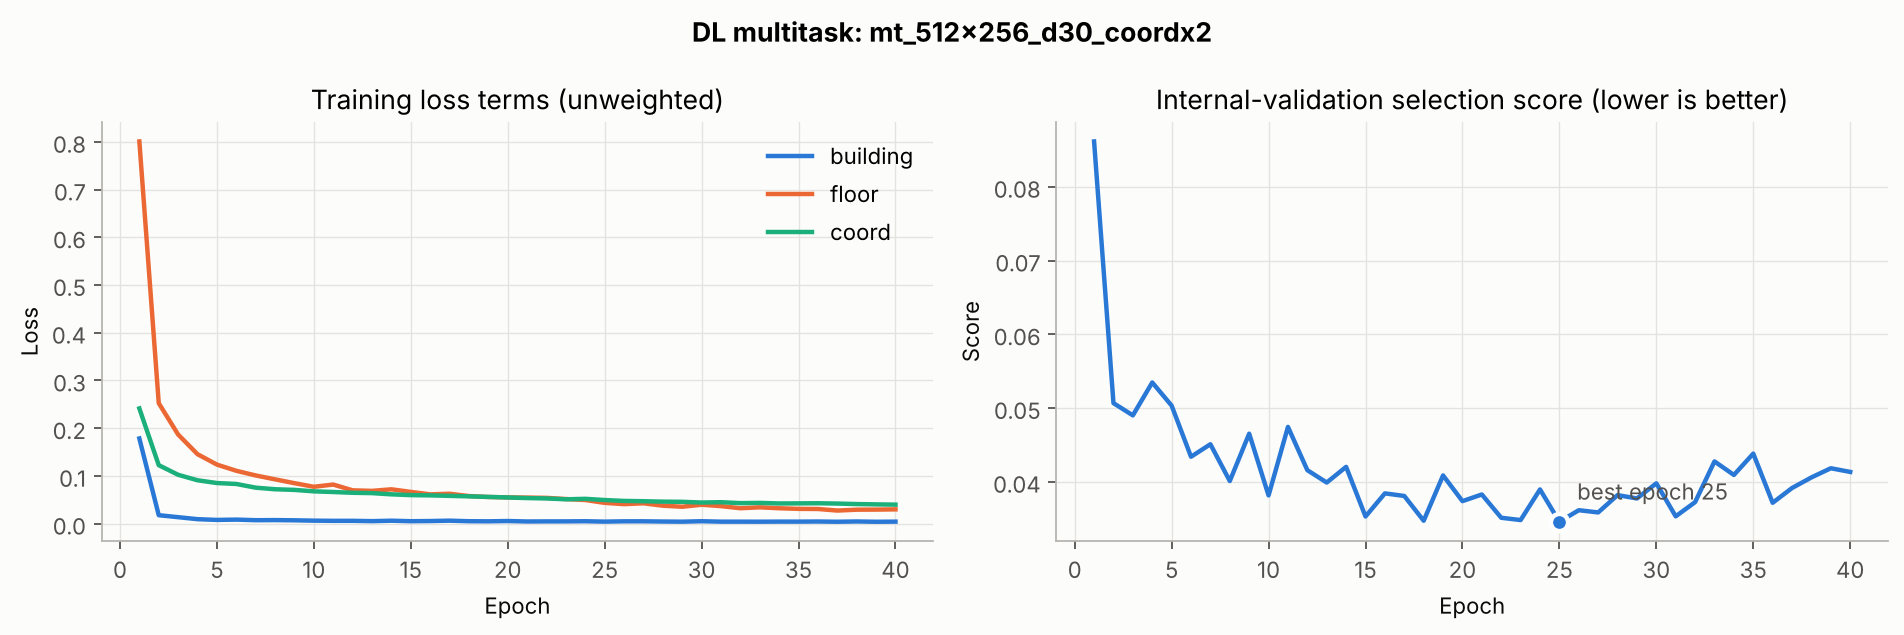

In [4]:
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_training_history.png")))

## 4. AML vs DL on identical rows

`DL single-task` combines the three separate DL_02–DL_04 networks (it has no joint building+floor value because the heads come from different networks).

,split,model,building_accuracy,building_macro_f1,floor_accuracy,floor_macro_f1,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,building_and_floor_accuracy,coordinate_unit
0,heldout_validation,DL multitask,0.999100,0.998835,0.906391,0.893491,8.553764,6.650163,11.879021,9.801745,0.906391,dataset coordinate units
1,heldout_validation,DL single-task (separate nets),0.997300,0.996819,0.902790,0.891672,6.756092,5.829574,9.837171,7.585233,NaN,dataset coordinate units
2,heldout_validation,AML Random Forest,0.997300,0.997126,0.889289,0.872655,8.096594,6.806426,11.583571,7.488385,0.887489,dataset coordinate units
3,internal_validation,DL multitask,0.999221,0.999247,0.978712,0.979529,8.134589,4.980521,10.281026,9.253705,0.978712,dataset coordinate units
4,internal_validation,DL single-task (separate nets),0.999481,0.999497,0.981828,0.981113,5.443756,4.423953,7.678409,5.999111,NaN,dataset coordinate units
5,internal_validation,AML Random Forest,0.999481,0.999497,0.964174,0.967825,5.914234,5.060706,8.578616,6.306672,0.964174,dataset coordinate units


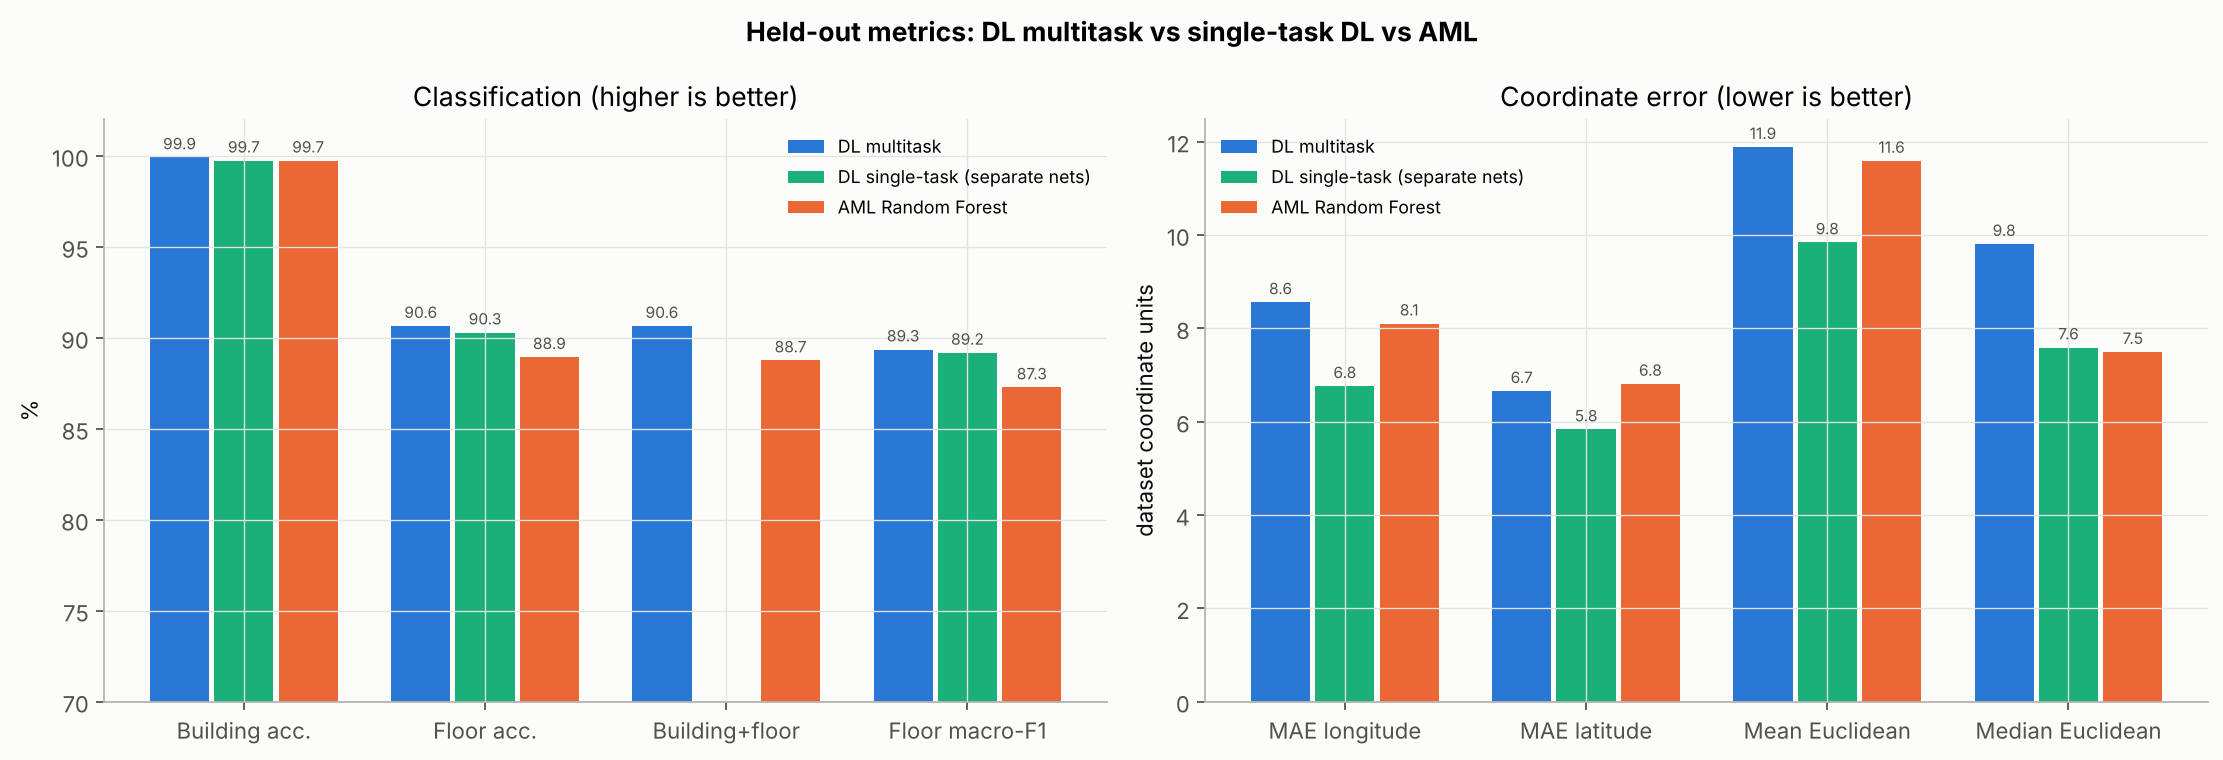

In [5]:
display(result["comparison"])
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_heldout_metric_comparison.png")))

### Paired, row-aligned significance checks (held-out)

Discordant counts and exact McNemar p-values for correctness; bootstrap 95% CI for the mean paired difference in Euclidean error (DL − AML; negative favours DL).

In [6]:
import json
print(json.dumps(result["paired"], indent=2))

{
  "internal_validation": {
    "n_rows": 3852,
    "building": {
      "dl_correct_aml_wrong": 2,
      "dl_wrong_aml_correct": 3,
      "mcnemar_exact_p": 1.0
    },
    "floor": {
      "dl_correct_aml_wrong": 89,
      "dl_wrong_aml_correct": 33,
      "mcnemar_exact_p": 4.040347038076119e-07
    },
    "building_and_floor": {
      "dl_correct_aml_wrong": 89,
      "dl_wrong_aml_correct": 33,
      "mcnemar_exact_p": 4.040347038076119e-07
    },
    "coordinate": {
      "mean_diff_dl_minus_aml": 1.7024102574720608,
      "ci95_low": 1.4511588573244485,
      "ci95_high": 1.9413546092416059,
      "share_rows_dl_closer": 0.3590342679127726,
      "unit": "dataset coordinate units"
    }
  },
  "heldout_validation": {
    "n_rows": 1111,
    "building": {
      "dl_correct_aml_wrong": 3,
      "dl_wrong_aml_correct": 1,
      "mcnemar_exact_p": 0.625
    },
    "floor": {
      "dl_correct_aml_wrong": 37,
      "dl_wrong_aml_correct": 18,
      "mcnemar_exact_p": 0.014453833533827

## 5. Floor confusion matrices (held-out)

,0,1,2,3,4
actual,,,,,
0,117,11,4,0,0
1,11,411,39,1,0
2,1,7,286,12,0
3,0,0,7,163,2
4,1,0,0,8,30


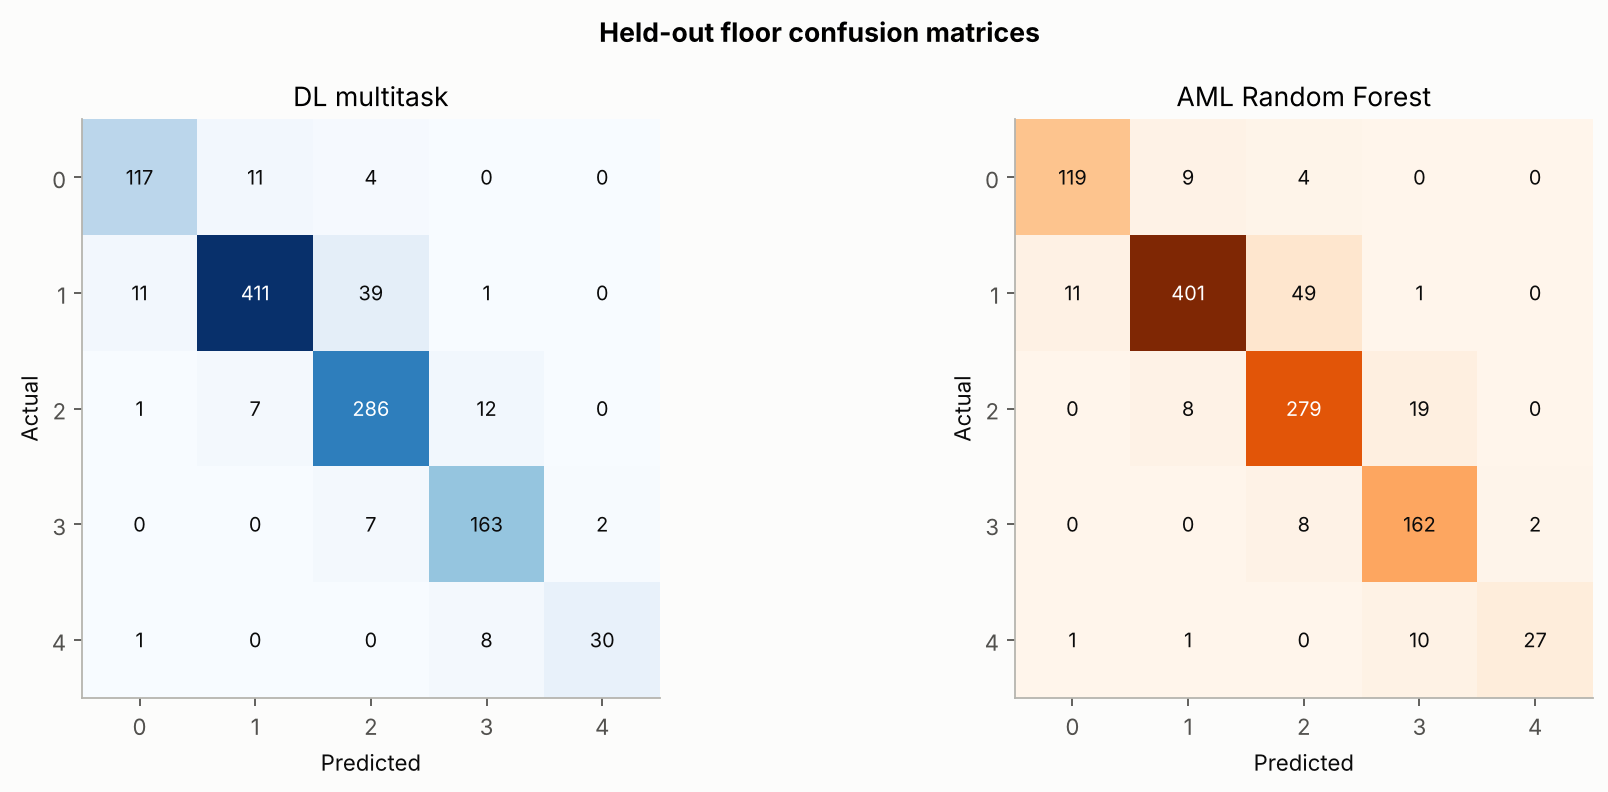

In [7]:
display(result["cm_floor"])
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_heldout_floor_confusion_dl_vs_aml.png")))

## 6. Coordinate error maps and distributions (held-out)

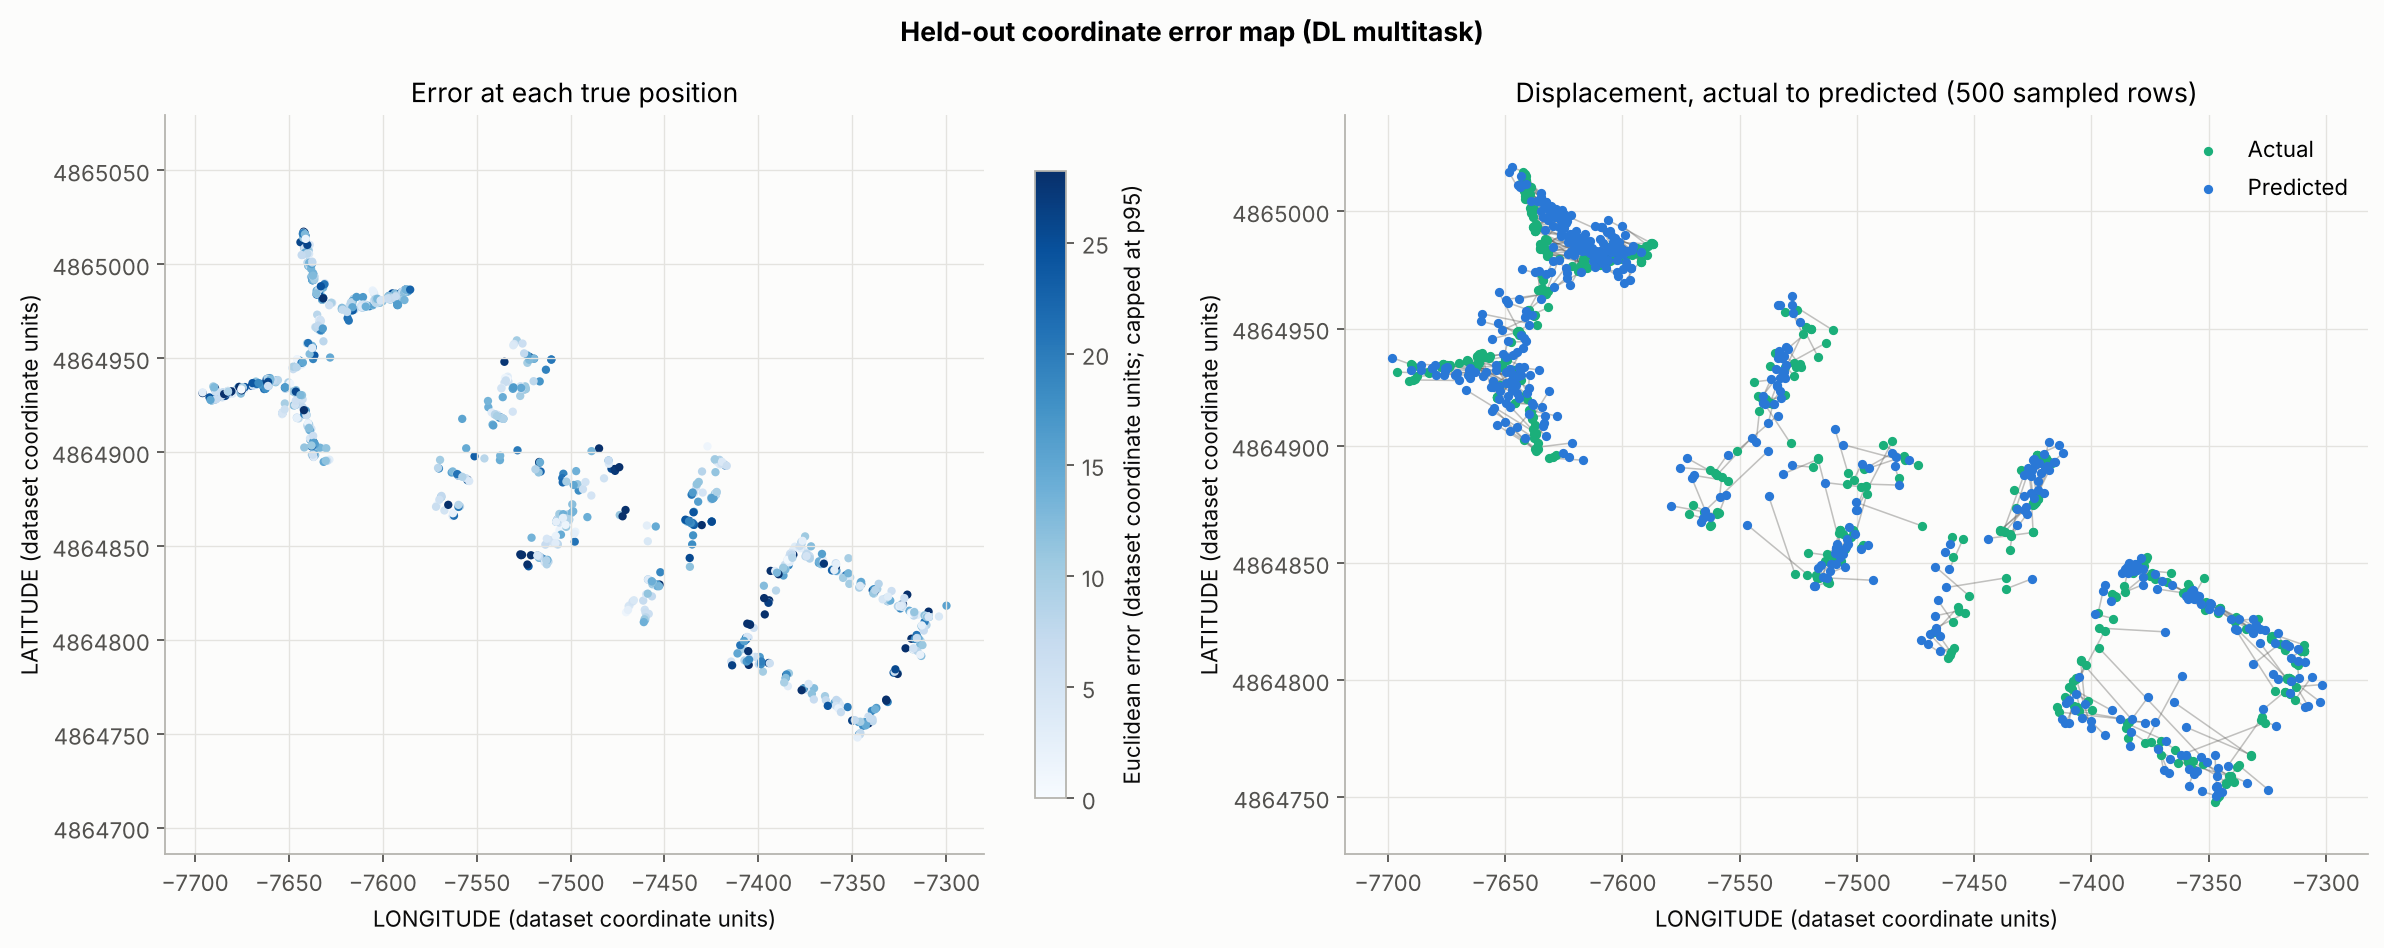

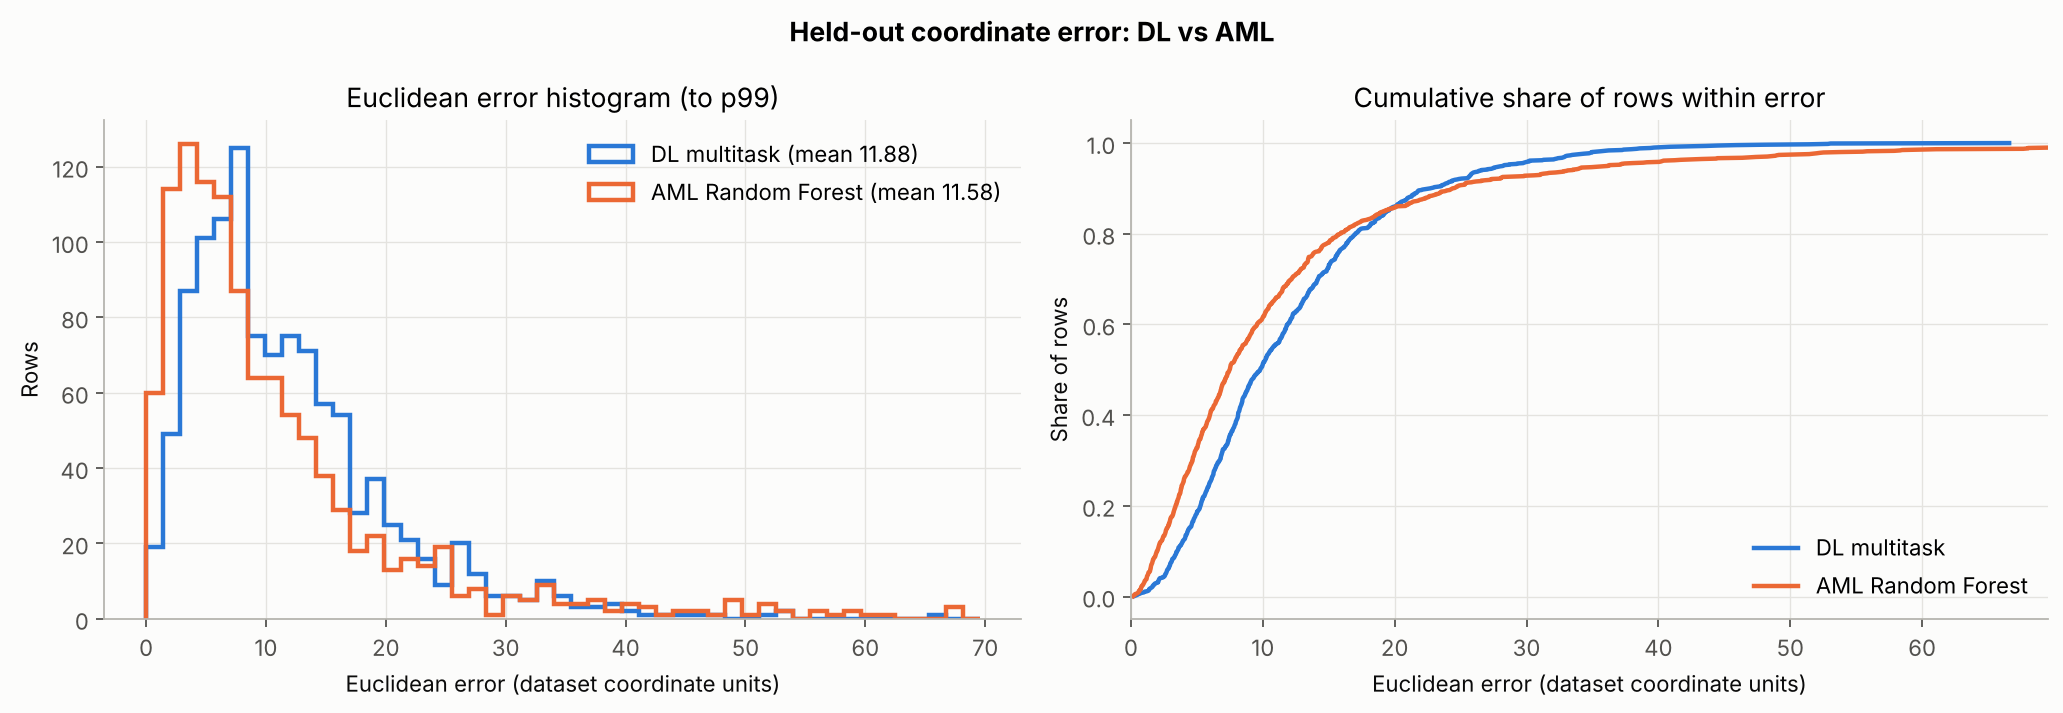

In [8]:
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_heldout_error_map.png")))
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_heldout_error_distribution_dl_vs_aml.png")))

## 7. Hierarchical building/floor error analysis

,split,hierarchy_outcome,n_rows,proportion,mean_coordinate_error,median_coordinate_error,coordinate_unit
0,internal_validation,both_correct,3770,0.978712,10.070872,9.208794,dataset coordinate units
1,internal_validation,building_correct_floor_wrong,79,0.020509,14.986198,13.881866,dataset coordinate units
2,internal_validation,building_wrong_floor_correct,0,0.000000,NaN,NaN,dataset coordinate units
3,internal_validation,both_wrong,3,0.000779,150.471898,159.716308,dataset coordinate units
4,heldout_validation,both_correct,1007,0.906391,11.265419,9.267211,dataset coordinate units
5,heldout_validation,building_correct_floor_wrong,103,0.092709,17.879331,14.593844,dataset coordinate units
6,heldout_validation,building_wrong_floor_correct,0,0.000000,NaN,NaN,dataset coordinate units
7,heldout_validation,both_wrong,1,0.000900,11.743644,11.743644,dataset coordinate units


,split,building_true,floor_true,n_rows,building_accuracy,floor_accuracy,joint_building_floor_accuracy,conditional_floor_accuracy_given_building_correct,mean_coordinate_error,median_coordinate_error
0,heldout_validation,0,0,78,1.000000,0.910256,0.910256,0.910256,13.620410,11.914892
1,heldout_validation,0,1,208,1.000000,0.971154,0.971154,0.971154,11.704027,10.059692
2,heldout_validation,0,2,165,1.000000,0.963636,0.963636,0.963636,9.925333,8.984216
3,heldout_validation,0,3,85,1.000000,0.941176,0.941176,0.941176,11.946572,10.479110
4,heldout_validation,1,0,30,0.966667,0.800000,0.800000,0.827586,11.722853,7.004619
5,heldout_validation,1,1,143,1.000000,0.706294,0.706294,0.706294,11.233003,10.235434
6,heldout_validation,1,2,87,1.000000,0.908046,0.908046,0.908046,13.337263,9.705497
7,heldout_validation,1,3,47,1.000000,0.957447,0.957447,0.957447,12.116135,10.705806
8,heldout_validation,2,0,24,1.000000,0.916667,0.916667,0.916667,12.940568,8.426767
9,heldout_validation,2,1,111,1.000000,0.972973,0.972973,0.972973,9.949870,8.243688


,floor_gap,n_rows
0,0,1007
1,1,97
2,2,5
3,4,1


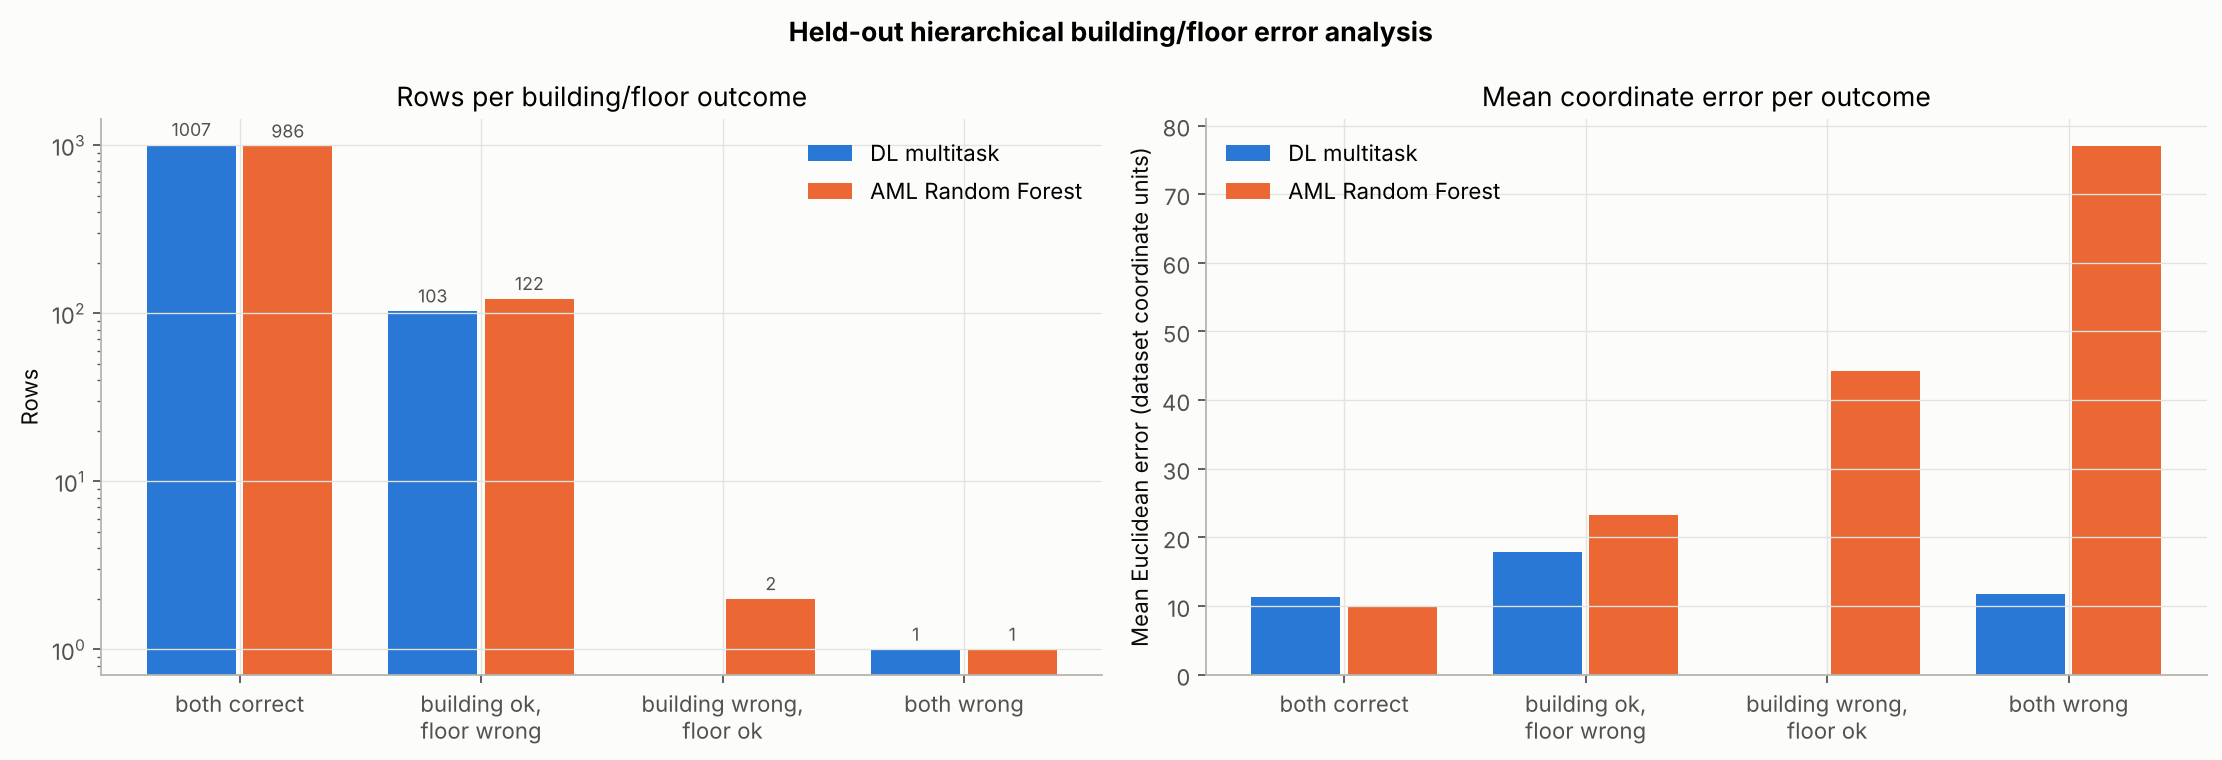

In [9]:
display(result["hierarchy"])
display(pd.read_csv(C.TABLES_DIR / "dl_05_multitask_hierarchical_by_building_floor.csv"))
display(pd.read_csv(C.TABLES_DIR / "dl_05_multitask_heldout_floor_error_distance.csv"))
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_hierarchical_dl_vs_aml.png")))

## 8. Seed variability of the frozen configuration (held-out)

In [10]:
display(result["seeds"])
display(result["seeds"].drop(columns=["seed", "best_epoch"]).agg(["mean", "std"]))

,seed,best_epoch,building_accuracy,building_macro_f1,floor_accuracy,floor_macro_f1,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,building_and_floor_accuracy
0,42,25,0.9991,0.998835,0.906391,0.893491,8.553764,6.650163,11.879021,9.801745,0.906391
1,7,23,0.9991,0.998835,0.896490,0.881885,8.815970,7.207010,12.395602,10.424349,0.896490
2,2026,25,0.9991,0.998835,0.900990,0.889418,8.536907,6.789208,11.939547,9.974965,0.900990


,building_accuracy,building_macro_f1,floor_accuracy,floor_macro_f1,mae_longitude,mae_latitude,mean_euclidean_error,median_euclidean_error,building_and_floor_accuracy
mean,0.9991,0.998835,0.901290,0.888265,8.635547,6.882127,12.071390,10.067019,0.901290
std,0.0000,0.000000,0.004957,0.005888,0.156478,0.289819,0.282402,0.321348,0.004957


## 9. Post-hoc robustness by identifier

`USERID`/`PHONEID` are never model inputs. On the held-out file `USERID` is a placeholder (`0`) so only `PHONEID` is analysed there; small groups give noisy estimates, and phone identity is confounded with collection time and location, so differences are descriptive, not causal.

,split,group_column,group,n_rows,group_seen_in_internal_train,building_accuracy,floor_accuracy,mean_euclidean_error,median_euclidean_error
34,heldout_validation,PHONEID,0,120,False,1.000000,0.833333,13.031844,11.840756
35,heldout_validation,PHONEID,2,52,False,1.000000,0.826923,12.134287,9.686588
36,heldout_validation,PHONEID,4,69,False,1.000000,0.913043,8.821564,8.451431
37,heldout_validation,PHONEID,5,17,False,1.000000,0.764706,11.849518,11.294863
38,heldout_validation,PHONEID,9,77,False,1.000000,0.948052,8.844183,7.405060
39,heldout_validation,PHONEID,12,70,False,1.000000,0.914286,12.246331,10.480592
40,heldout_validation,PHONEID,13,369,True,1.000000,0.934959,10.917168,9.267211
41,heldout_validation,PHONEID,14,28,True,1.000000,0.821429,16.554927,13.689986
42,heldout_validation,PHONEID,15,36,False,1.000000,0.944444,8.916295,8.489780
43,heldout_validation,PHONEID,20,213,False,0.995305,0.901408,14.287942,11.743644


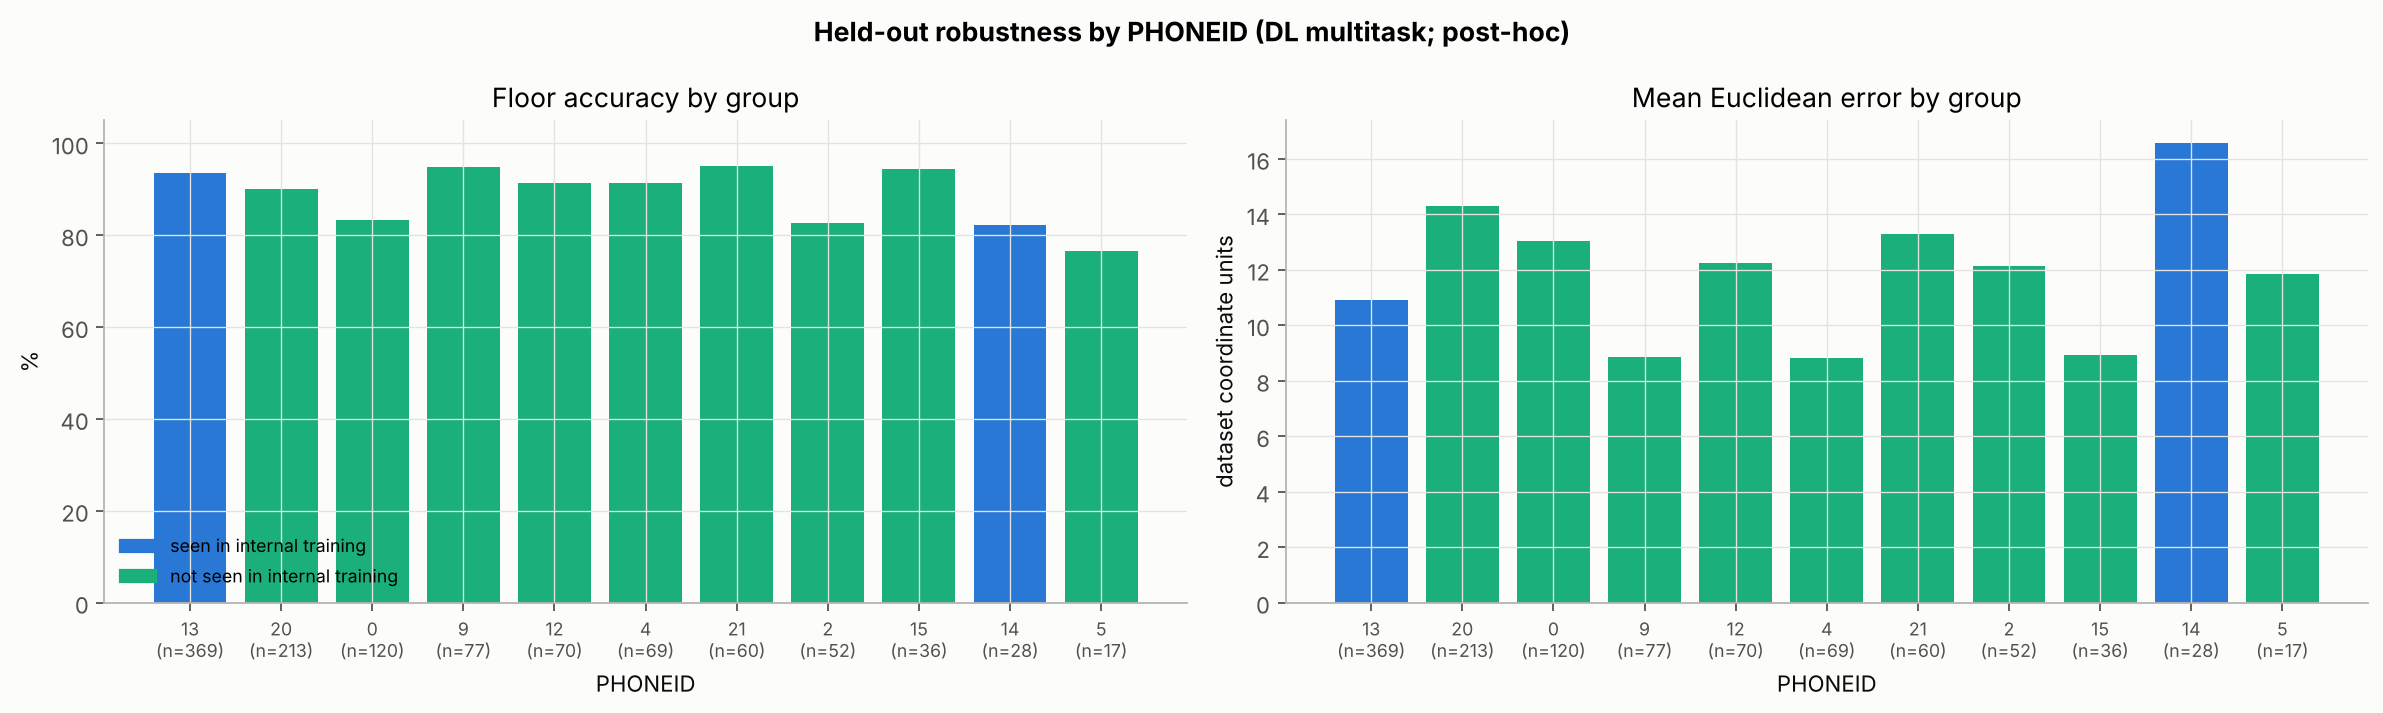

In [11]:
rob = result["robustness"]
display(rob[rob.split == "heldout_validation"])
display(Image(filename=str(C.FIGURES_DIR / "dl_05_multitask_heldout_robustness_by_phone.png")))

## Conclusion and limitations

* All selection used internal validation; the held-out partition was scored once per frozen model.
* Scores describe the supplied UJIIndoorLoc partition only. The held-out file shares no identical fingerprints with training but was collected later with mostly different phones; this is a temporal/device-shift test, not a test of unseen buildings.
* Coordinate errors are in dataset coordinate units, not verified metres.
* Interpretation of these numbers is in `docs/DL_PIPELINE.md` and the README.